<a href="https://colab.research.google.com/github/khushbunaz/iot-xai-anomaly-detection/blob/main/Anomaly_detection_MSC_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Step 0: Connect to Permanent Storage
Mounts Google Drive and switches to a permanent project folder, so all downloaded and processed data survives Colab session resets.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/content/drive/MyDrive/iot_project', exist_ok=True)
os.chdir('/content/drive/MyDrive/iot_project')
print(f"Current working directory: {os.getcwd()}")

Mounted at /content/drive
Current working directory: /content/drive/MyDrive/iot_project


In [18]:
import numpy as np, json
X_train=np.load("X_train.npy"); X_test=np.load("X_test.npy")
y_train=np.load("y_train.npy"); y_test=np.load("y_test.npy")

print("test counts [benign, attack]:", np.bincount(y_test))

res=json.load(open("results_baseline.json"))
for k,v in res.items():
    tn,fp,fn,tp=np.array(v["confusion_matrix"]).ravel()
    print(k,"TN",tn,"FP",fp,"FN",fn,"TP",tp,"FPR",round(fp/(fp+tn),4))

# overlap check: test rows that also appear in the training set
def hashes(X):
    Xr=np.round(X,3).astype(np.float32)
    return np.array([hash(r.tobytes()) for r in Xr])
h_tr=set(hashes(X_train)); h_te=hashes(X_test)
dup=np.isin(h_te,np.array(list(h_tr)))
print("share of test rows also in train:",round(dup.mean(),4))
print("benign:",round(dup[y_test==0].mean(),4),"attack:",round(dup[y_test==1].mean(),4))

test counts [benign, attack]: [ 23615 276385]
statistical_baseline TN 21156 FP 2459 FN 27 TP 276358 FPR 0.1041
isolation_forest TN 21306 FP 2309 FN 78810 TP 197575 FPR 0.0978
one_class_svm TN 22448 FP 1167 FN 35 TP 276350 FPR 0.0494
autoencoder TN 22471 FP 1144 FN 76909 TP 199476 FPR 0.0484
lstm_autoencoder TN 15 FP 23600 FN 1 TP 276380 FPR 0.9994
share of test rows also in train: 0.4085
benign: 0.0391 attack: 0.4401


## Step 1: Install Required Packages
Installs all Python libraries needed across the whole pipeline, plus the unrar system tool.

In [3]:
!pip install pandas numpy scikit-learn matplotlib seaborn tensorflow shap joblib pyarrow -q
!apt-get install -y unrar -q

Reading package lists...
Building dependency tree...
Reading state information...
unrar is already the newest version (1:7.0.7-1build1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


## Step 2: Download and Extract the N-BaIoT Dataset
Downloads the dataset zip directly from the UCI ML Repository (the automated API doesn't support this dataset, so this is a direct download) and extracts it.

In [4]:
import urllib.request
import zipfile
import os

URL = "https://archive.ics.uci.edu/static/public/442/detection+of+iot+botnet+attacks+n+baiot.zip"
ZIP_PATH = "nbaiot.zip"
EXTRACT_DIR = "nbaiot_raw"

print("Downloading...")
urllib.request.urlretrieve(URL, ZIP_PATH)
print("Download complete:", os.path.getsize(ZIP_PATH) / (1024 * 1024), "MB")

print("Extracting...")
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)
print("Done.")

Downloading...
Download complete: 1690.7910604476929 MB
Extracting...
Done.


## Step 3: Extract Attack Data (.rar files) Into Separate Subfolders
Each device folder contains separate Gafgyt and Mirai attack archives. Extracting each into its own subfolder avoids a file-naming collision between the two attack types.

In [5]:
import subprocess
from pathlib import Path

RAW_DIR = Path("nbaiot_raw")
rar_files = list(RAW_DIR.rglob("*.rar"))
print(f"Found {len(rar_files)} .rar files to extract")

for i, rar_path in enumerate(rar_files, 1):
    subfolder_name = rar_path.stem
    dest_dir = rar_path.parent / subfolder_name
    dest_dir.mkdir(exist_ok=True)
    result = subprocess.run(
        ["unrar", "x", "-y", str(rar_path), str(dest_dir) + "/"],
        capture_output=True, text=True
    )
    if result.returncode != 0:
        print(f"  FAILED: {rar_path}")
        print(result.stderr[:300])
    if i % 5 == 0 or i == len(rar_files):
        print(f"  Extracted {i}/{len(rar_files)}...")

csv_files = list(RAW_DIR.rglob("*.csv"))
gafgyt_count = sum(1 for f in csv_files if "gafgyt" in str(f).lower())
mirai_count = sum(1 for f in csv_files if "mirai" in str(f).lower())
print(f"Total CSVs: {len(csv_files)}, gafgyt: {gafgyt_count}, mirai: {mirai_count}")

Found 16 .rar files to extract
  Extracted 5/16...
  Extracted 10/16...
  Extracted 15/16...
  Extracted 16/16...
Total CSVs: 90, gafgyt: 45, mirai: 35


## Step 4: Load, Label, and Combine the Dataset
Walks all 90 CSV files, correctly labels each as benign or a specific Gafgyt/Mirai attack type, and writes the combined dataset to disk incrementally to avoid memory issues.

In [6]:
import pandas as pd
import numpy as np
from pathlib import Path
import pyarrow as pa
import pyarrow.parquet as pq

RAW_DIR = Path("nbaiot_raw")
csv_files = list(RAW_DIR.rglob("*.csv"))
print(f"Found {len(csv_files)} CSV files under {RAW_DIR}/")

def label_from_path(path: Path) -> str:
    name = path.stem.lower()
    full = str(path).lower()
    if "benign" in name:
        return "benign"
    if "gafgyt" in full or "bashlite" in full:
        return f"gafgyt_{name}"
    if "mirai" in full:
        return f"mirai_{name}"
    return f"unknown_{path.parent.name.lower()}_{name}"

feature_writer = None
label_writer = None
LABEL_SCHEMA = pa.schema([("label", pa.string())])

for i, csv_path in enumerate(csv_files, 1):
    try:
        df = pd.read_csv(csv_path, dtype=np.float32)
    except Exception as e:
        print(f"  Skipping {csv_path} (read error: {e})")
        continue
    if len(df) == 0:
        continue

    label = label_from_path(csv_path)
    labels_df = pd.DataFrame({"label": [label] * len(df)})

    feat_table = pa.Table.from_pandas(df, preserve_index=False)
    label_table = pa.Table.from_pandas(labels_df, schema=LABEL_SCHEMA, preserve_index=False)

    if feature_writer is None:
        feature_writer = pq.ParquetWriter("nbaiot_features.parquet", feat_table.schema)
        label_writer = pq.ParquetWriter("nbaiot_labels.parquet", LABEL_SCHEMA)

    if feat_table.schema != feature_writer.schema:
        feat_table = feat_table.cast(feature_writer.schema)

    feature_writer.write_table(feat_table)
    label_writer.write_table(label_table)
    del df, labels_df, feat_table, label_table

    if i % 10 == 0 or i == len(csv_files):
        print(f"  Processed {i}/{len(csv_files)} files...")

feature_writer.close()
label_writer.close()
print("\nSaved nbaiot_features.parquet and nbaiot_labels.parquet")

labels_only = pq.read_table("nbaiot_labels.parquet").to_pandas()
print("\n--- Label distribution ---")
print(labels_only["label"].value_counts())

Found 90 CSV files under nbaiot_raw/
  Processed 10/90 files...
  Processed 20/90 files...
  Processed 30/90 files...
  Processed 40/90 files...
  Processed 50/90 files...
  Processed 60/90 files...
  Processed 70/90 files...
  Processed 80/90 files...
  Processed 90/90 files...

Saved nbaiot_features.parquet and nbaiot_labels.parquet

--- Label distribution ---
label
mirai_udp         1229999
gafgyt_udp         946366
gafgyt_tcp         859850
mirai_syn          733299
mirai_ack          643821
benign             555932
mirai_scan         537979
mirai_udpplain     523304
gafgyt_combo       515156
gafgyt_junk        261789
gafgyt_scan        255111
Name: count, dtype: int64


## Step 5: Verify Dataset Integrity
Confirms the final dataset shape (7,062,606 rows x 115 features), checks for missing values, and produces the class distribution chart.

=== Shape ===
Features: (7062606, 115)
Labels: (7062606, 1)

=== Missing values ===
0 missing values across all features

=== Label distribution ===
label
mirai_udp         1229999
gafgyt_udp         946366
gafgyt_tcp         859850
mirai_syn          733299
mirai_ack          643821
benign             555932
mirai_scan         537979
mirai_udpplain     523304
gafgyt_combo       515156
gafgyt_junk        261789
gafgyt_scan        255111
Name: count, dtype: int64

As percentage:
label
mirai_udp         17.42
gafgyt_udp        13.40
gafgyt_tcp        12.17
mirai_syn         10.38
mirai_ack          9.12
benign             7.87
mirai_scan         7.62
mirai_udpplain     7.41
gafgyt_combo       7.29
gafgyt_junk        3.71
gafgyt_scan        3.61
Name: count, dtype: float64


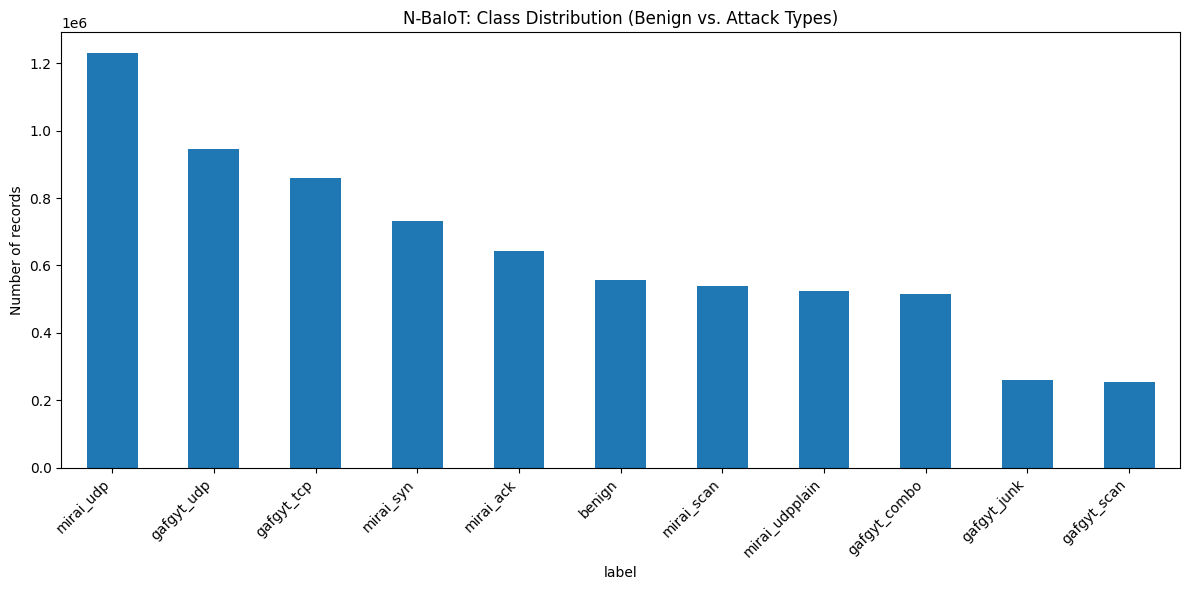


Saved class_distribution.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

X = pd.read_parquet("nbaiot_features.parquet")
y = pd.read_parquet("nbaiot_labels.parquet")

print("=== Shape ===")
print("Features:", X.shape)
print("Labels:", y.shape)

print("\n=== Missing values ===")
print(X.isnull().sum().sum(), "missing values across all features")

print("\n=== Label distribution ===")
counts = y["label"].value_counts()
print(counts)
print("\nAs percentage:")
print((counts / counts.sum() * 100).round(2))

plt.figure(figsize=(12, 6))
counts.plot(kind="bar")
plt.title("N-BaIoT: Class Distribution (Benign vs. Attack Types)")
plt.ylabel("Number of records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()
print("\nSaved class_distribution.png")

In [7]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir('/content/drive/MyDrive/iot_project')
print(os.getcwd())
!ls -lh

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/iot_project
total 2.6G
-rw-------  1 root root   13 Oct 29 15:14 best_model.txt
-rw-------  1 root root  70K Oct 23 09:48 class_distribution.png
-rw-------  1 root root 2.0K Oct 29 14:21 feature_names.pkl
-rw-------  1 root root 250K Oct 29 14:35 model_autoencoder.keras
-rw-------  1 root root  75K Oct 29 15:14 model_comparison_chart.png
-rw-------  1 root root  327 Oct 29 15:14 model_comparison.csv
-rw-------  1 root root 1.5M Oct 29 14:26 model_isolation_forest.pkl
-rw-------  1 root root 403K Oct 29 14:38 model_lstm_autoencoder.keras
-rw-------  1 root root 941K Oct 29 14:28 model_one_class_svm.pkl
-rw-------  1 root root 1.5G Oct 30 00:53 nbaiot_features.parquet
-rw-------  1 root root  38K Oct 30 00:53 nbaiot_labels.parquet
drwx------ 11 root root 4.0K Oct 30 00:40 nbaiot_raw
-rw-------  1 root root 635M Oct 30 00:38 nbaiot.zip
-rw

## Step 6: Preprocessing - Framing, Sampling, Split, and Benign-Only Scaling
Frames the problem as binary (benign vs. anomalous), draws a stratified 1,000,000-row sample to fit available memory, splits into train/test sets, and fits the scaler using only benign training data as the reference for 'normal' traffic - the correct approach for anomaly detection.

In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib
import gc

SAMPLE_SIZE = 1_000_000

print("Loading labels...")
y = pd.read_parquet("nbaiot_labels.parquet")
y_binary = (y["label"] != "benign").astype(int).values
del y
gc.collect()

sample_idx, _ = train_test_split(
    np.arange(len(y_binary)), train_size=SAMPLE_SIZE, random_state=42, stratify=y_binary
)
y_binary_sample = y_binary[sample_idx]
del y_binary
gc.collect()

print("Loading features (float32) for sampled rows only...")
X = pd.read_parquet("nbaiot_features.parquet").astype(np.float32)
feature_names = list(X.columns)
X_sample = X.values[sample_idx]
del X
gc.collect()

X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_binary_sample, test_size=0.3, random_state=42, stratify=y_binary_sample
)
del X_sample, y_binary_sample
gc.collect()

print("Fitting scaler on BENIGN-ONLY training data...")
X_train_benign_raw = X_train[y_train == 0]
scaler = StandardScaler()
scaler.fit(X_train_benign_raw)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
del X_train, X_test, X_train_benign_raw
gc.collect()

np.save("X_train.npy", X_train_scaled)
np.save("X_test.npy", X_test_scaled)
np.save("y_train.npy", y_train)
np.save("y_test.npy", y_test)
joblib.dump(scaler, "scaler.pkl")
joblib.dump(feature_names, "feature_names.pkl")

print(f"\nSaved (corrected): X_train {X_train_scaled.shape}, X_test {X_test_scaled.shape}")

Loading labels...
Loading features (float32) for sampled rows only...
Fitting scaler on BENIGN-ONLY training data...

Saved (corrected): X_train (700000, 115), X_test (300000, 115)


## Step 7: Phase 3 - Baseline Models
Trains and evaluates three baseline anomaly detection approaches: a simple statistical
threshold, Isolation Forest, and One-Class SVM. Results are saved for later comparison
against the deep learning models.

In [9]:
import numpy as np
import joblib
import json
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

X_train = np.load("X_train.npy")
X_test = np.load("X_test.npy")
y_train = np.load("y_train.npy")
y_test = np.load("y_test.npy")

results = {}

def evaluate(name, y_true, y_pred, y_score=None):
    metrics = {
        "precision": round(precision_score(y_true, y_pred, zero_division=0), 4),
        "recall": round(recall_score(y_true, y_pred, zero_division=0), 4),
        "f1": round(f1_score(y_true, y_pred, zero_division=0), 4),
        "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
    }
    if y_score is not None:
        metrics["roc_auc"] = round(roc_auc_score(y_true, y_score), 4)
        metrics["auc_pr"] = round(average_precision_score(y_true, y_score), 4)
    results[name] = metrics
    print(f"\n{name}:")
    for k, v in metrics.items():
        print(f"  {k}: {v}")

In [10]:
# --- 1. Statistical baseline ---
print("=== Statistical Baseline (z-score) ===")
z_scores = np.abs(X_test)
baseline_pred = (z_scores.max(axis=1) > 4.0).astype(int)
baseline_score = z_scores.max(axis=1)
evaluate("statistical_baseline", y_test, baseline_pred, baseline_score)

=== Statistical Baseline (z-score) ===

statistical_baseline:
  precision: 0.9912
  recall: 0.9999
  f1: 0.9955
  confusion_matrix: [[21156, 2459], [27, 276358]]
  roc_auc: 0.9995
  auc_pr: 1.0


In [11]:
print("\n=== Isolation Forest ===")
iso = IsolationForest(n_estimators=200, contamination="auto", random_state=42, n_jobs=-1)
iso.fit(X_train[y_train == 0])
iso_pred = (iso.predict(X_test) == -1).astype(int)
iso_score = -iso.score_samples(X_test)
evaluate("isolation_forest", y_test, iso_pred, iso_score)
joblib.dump(iso, "model_isolation_forest.pkl")



=== Isolation Forest ===

isolation_forest:
  precision: 0.9884
  recall: 0.7149
  f1: 0.8297
  confusion_matrix: [[21306, 2309], [78810, 197575]]
  roc_auc: 0.9319
  auc_pr: 0.9901


['model_isolation_forest.pkl']

In [12]:
# --- 3. One-Class SVM ---
print("\n=== One-Class SVM ===")
X_train_benign = X_train[y_train == 0]
if len(X_train_benign) > 20000:
    rng = np.random.default_rng(42)
    idx = rng.choice(len(X_train_benign), 20000, replace=False)
    X_train_benign = X_train_benign[idx]

ocsvm = OneClassSVM(kernel="rbf", nu=0.05, gamma="scale")
ocsvm.fit(X_train_benign)
ocsvm_pred = (ocsvm.predict(X_test) == -1).astype(int)
ocsvm_score = -ocsvm.decision_function(X_test)
evaluate("one_class_svm", y_test, ocsvm_pred, ocsvm_score)
joblib.dump(ocsvm, "model_one_class_svm.pkl")

with open("results_baseline.json", "w") as f:
    json.dump(results, f, indent=2)
print("\nSaved results_baseline.json, model_isolation_forest.pkl, model_one_class_svm.pkl")


=== One-Class SVM ===

one_class_svm:
  precision: 0.9958
  recall: 0.9999
  f1: 0.9978
  confusion_matrix: [[22448, 1167], [35, 276350]]
  roc_auc: 0.993
  auc_pr: 0.9994

Saved results_baseline.json, model_isolation_forest.pkl, model_one_class_svm.pkl


## Step 8: Phase 3 continued - Autoencoder
Trains a neural network to reconstruct benign traffic patterns. Anomalies are detected as
traffic the model struggles to reconstruct accurately (high reconstruction error).

In [13]:
import numpy as np
import json
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

tf.random.set_seed(42)

X_train = np.load("X_train.npy")
X_test = np.load("X_test.npy")
y_train = np.load("y_train.npy")
y_test = np.load("y_test.npy")

n_features = X_train.shape[1]
X_train_benign = X_train[y_train == 0]

# Load existing results to add to (keeps all models in one place for comparison)
with open("results_baseline.json") as f:
    results = json.load(f)

def evaluate(name, y_true, y_pred, y_score=None):
    metrics = {
        "precision": round(precision_score(y_true, y_pred, zero_division=0), 4),
        "recall": round(recall_score(y_true, y_pred, zero_division=0), 4),
        "f1": round(f1_score(y_true, y_pred, zero_division=0), 4),
        "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
    }
    if y_score is not None:
        metrics["roc_auc"] = round(roc_auc_score(y_true, y_score), 4)
        metrics["auc_pr"] = round(average_precision_score(y_true, y_score), 4)
    results[name] = metrics
    print(f"\n{name}:")
    for k, v in metrics.items():
        print(f"  {k}: {v}")

print("=== Autoencoder ===")

# Hold out a slice of benign training data to calibrate the anomaly threshold
split = int(len(X_train_benign) * 0.9)
X_ae_train, X_ae_val = X_train_benign[:split], X_train_benign[split:]

encoding_dim = max(8, n_features // 4)
inputs = keras.Input(shape=(n_features,))
x = layers.Dense(64, activation="relu")(inputs)
x = layers.Dense(encoding_dim, activation="relu")(x)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(n_features, activation="linear")(x)
autoencoder = keras.Model(inputs, outputs)
autoencoder.compile(optimizer="adam", loss="mse")

autoencoder.fit(
    X_ae_train, X_ae_train,
    epochs=20, batch_size=256, shuffle=True,
    validation_data=(X_ae_val, X_ae_val),
    callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)],
    verbose=2,
)

recon_val = autoencoder.predict(X_ae_val, verbose=0)
errors_val = np.mean(np.square(X_ae_val - recon_val), axis=1)
threshold = np.percentile(errors_val, 95)
print(f"Anomaly threshold (95th percentile of benign val error): {threshold:.4f}")

recon_test = autoencoder.predict(X_test, verbose=0)
errors_test = np.mean(np.square(X_test - recon_test), axis=1)
ae_pred = (errors_test > threshold).astype(int)
evaluate("autoencoder", y_test, ae_pred, errors_test)
autoencoder.save("model_autoencoder.keras")

with open("results_baseline.json", "w") as f:
    json.dump(results, f, indent=2)

print("\nSaved model_autoencoder.keras and updated results_baseline.json")

=== Autoencoder ===
Epoch 1/20
194/194 - 4s - 20ms/step - loss: 0.3960 - val_loss: 0.1502
Epoch 2/20
194/194 - 2s - 10ms/step - loss: 0.1075 - val_loss: 0.0810
Epoch 3/20
194/194 - 1s - 5ms/step - loss: 0.0707 - val_loss: 0.0604
Epoch 4/20
194/194 - 1s - 7ms/step - loss: 0.0551 - val_loss: 0.0491
Epoch 5/20
194/194 - 1s - 4ms/step - loss: 0.0462 - val_loss: 0.0424
Epoch 6/20
194/194 - 1s - 5ms/step - loss: 0.0404 - val_loss: 0.0377
Epoch 7/20
194/194 - 1s - 5ms/step - loss: 0.0362 - val_loss: 0.0343
Epoch 8/20
194/194 - 1s - 5ms/step - loss: 0.0330 - val_loss: 0.0314
Epoch 9/20
194/194 - 1s - 5ms/step - loss: 0.0303 - val_loss: 0.0291
Epoch 10/20
194/194 - 1s - 5ms/step - loss: 0.0281 - val_loss: 0.0273
Epoch 11/20
194/194 - 1s - 5ms/step - loss: 0.0264 - val_loss: 0.0259
Epoch 12/20
194/194 - 1s - 5ms/step - loss: 0.0250 - val_loss: 0.0248
Epoch 13/20
194/194 - 1s - 7ms/step - loss: 0.0240 - val_loss: 0.0237
Epoch 14/20
194/194 - 1s - 7ms/step - loss: 0.0228 - val_loss: 0.0227
Epoch 1

## Step 9: Phase 3 continued - LSTM Sequential Detector
Trains an LSTM-based autoencoder that reconstructs short sequences (windows) of consecutive
traffic samples, aiming to capture temporal patterns that single-sample models miss.

In [14]:
import numpy as np
import json
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

X_train = np.load("X_train.npy")
X_test = np.load("X_test.npy")
y_train = np.load("y_train.npy")
y_test = np.load("y_test.npy")

n_features = X_train.shape[1]
X_train_benign = X_train[y_train == 0]

with open("results_baseline.json") as f:
    results = json.load(f)

def evaluate(name, y_true, y_pred, y_score):
    metrics = {
        "precision": round(precision_score(y_true, y_pred, zero_division=0), 4),
        "recall": round(recall_score(y_true, y_pred, zero_division=0), 4),
        "f1": round(f1_score(y_true, y_pred, zero_division=0), 4),
        "roc_auc": round(roc_auc_score(y_true, y_score), 4),
        "auc_pr": round(average_precision_score(y_true, y_score), 4),
        "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
    }
    results[name] = metrics
    print(f"\n{name}:")
    for k, v in metrics.items():
        print(f"  {k}: {v}")

print("=== LSTM Autoencoder ===")
WINDOW = 5

def make_windows(data, window):
    n = len(data) - window + 1
    return np.array([data[i:i + window] for i in range(n)])

X_lstm_train_full = make_windows(X_train_benign, WINDOW)
split_l = int(len(X_lstm_train_full) * 0.9)
X_lstm_train, X_lstm_val = X_lstm_train_full[:split_l], X_lstm_train_full[split_l:]
X_lstm_test = make_windows(X_test, WINDOW)
y_test_windows = y_test[WINDOW - 1:]

lstm_inputs = keras.Input(shape=(WINDOW, n_features))
x = layers.LSTM(32, activation="tanh", return_sequences=False)(lstm_inputs)
x = layers.RepeatVector(WINDOW)(x)
x = layers.LSTM(32, activation="tanh", return_sequences=True)(x)
lstm_outputs = layers.TimeDistributed(layers.Dense(n_features))(x)
lstm_ae = keras.Model(lstm_inputs, lstm_outputs)
lstm_ae.compile(optimizer="adam", loss="mse")

lstm_ae.fit(
    X_lstm_train, X_lstm_train,
    epochs=10, batch_size=256, shuffle=True,
    validation_data=(X_lstm_val, X_lstm_val),
    callbacks=[keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)],
    verbose=2,
)

recon_val_l = lstm_ae.predict(X_lstm_val, verbose=0)
errors_val_l = np.mean(np.square(X_lstm_val - recon_val_l), axis=(1, 2))
threshold_l = np.percentile(errors_val_l, 95)

recon_test_l = lstm_ae.predict(X_lstm_test, verbose=0)
errors_test_l = np.mean(np.square(X_lstm_test - recon_test_l), axis=(1, 2))
lstm_pred = (errors_test_l > threshold_l).astype(int)
evaluate("lstm_autoencoder", y_test_windows, lstm_pred, errors_test_l)
lstm_ae.save("model_lstm_autoencoder.keras")

with open("results_baseline.json", "w") as f:
    json.dump(results, f, indent=2)

print("\nSaved model_lstm_autoencoder.keras and updated results_baseline.json")

=== LSTM Autoencoder ===
Epoch 1/10
194/194 - 7s - 36ms/step - loss: 0.8878 - val_loss: 0.7980
Epoch 2/10
194/194 - 4s - 20ms/step - loss: 0.7003 - val_loss: 0.6156
Epoch 3/10
194/194 - 5s - 27ms/step - loss: 0.5517 - val_loss: 0.5119
Epoch 4/10
194/194 - 3s - 17ms/step - loss: 0.4694 - val_loss: 0.4476
Epoch 5/10
194/194 - 3s - 18ms/step - loss: 0.4157 - val_loss: 0.4025
Epoch 6/10
194/194 - 4s - 23ms/step - loss: 0.3784 - val_loss: 0.3712
Epoch 7/10
194/194 - 5s - 24ms/step - loss: 0.3530 - val_loss: 0.3507
Epoch 8/10
194/194 - 3s - 17ms/step - loss: 0.3344 - val_loss: 0.3371
Epoch 9/10
194/194 - 3s - 18ms/step - loss: 0.3199 - val_loss: 0.3250
Epoch 10/10
194/194 - 7s - 38ms/step - loss: 0.3083 - val_loss: 0.3149

lstm_autoencoder:
  precision: 0.9213
  recall: 1.0
  f1: 0.9591
  roc_auc: 0.6114
  auc_pr: 0.9457
  confusion_matrix: [[15, 23600], [1, 276380]]

Saved model_lstm_autoencoder.keras and updated results_baseline.json


## Step 10: Phase 4 - Comparative Evaluation
Compares all 5 models side by side. Models with near-random ROC-AUC (<0.7) are flagged and
excluded from best-model selection, since high F1/recall alone can be misleading for models
that simply flag most traffic as anomalous without genuinely discriminating.

=== Full Model Comparison (sorted by F1) ===
               model  precision  recall     f1  roc_auc  auc_pr  flagged
       one_class_svm     0.9958  0.9999 0.9978   0.9930  0.9994    False
statistical_baseline     0.9912  0.9999 0.9955   0.9995  1.0000    False
    lstm_autoencoder     0.9213  1.0000 0.9591   0.6114  0.9457     True
         autoencoder     0.9943  0.7217 0.8364   0.9695  0.9972    False
    isolation_forest     0.9884  0.7149 0.8297   0.9319  0.9901    False

/!\ FLAGGED (ROC-AUC < 0.7, excluded from best-model selection):
  - lstm_autoencoder: F1=0.9591 looks good, but ROC-AUC=0.6114 indicates it is not genuinely discriminating (likely flagging most traffic as anomalous).

Best-performing model (excluding flagged): one_class_svm


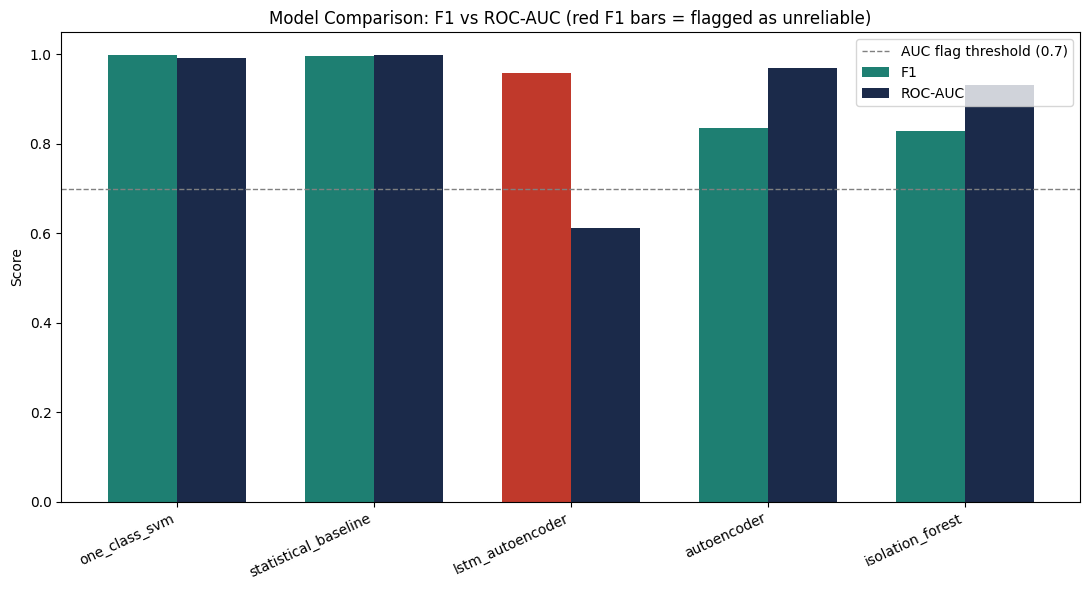


Saved model_comparison.csv, model_comparison_chart.png, best_model.txt


In [15]:
import json
import pandas as pd
import matplotlib.pyplot as plt

with open("results_baseline.json") as f:
    results = json.load(f)

rows = []
for model_name, metrics in results.items():
    rows.append({
        "model": model_name,
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
        "roc_auc": metrics.get("roc_auc"),
        "auc_pr": metrics.get("auc_pr"),
    })

comparison = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)

# Flag models with near-random ROC-AUC as unreliable, regardless of F1
AUC_FLAG_THRESHOLD = 0.70
comparison["flagged"] = comparison["roc_auc"] < AUC_FLAG_THRESHOLD

print("=== Full Model Comparison (sorted by F1) ===")
print(comparison.to_string(index=False))
comparison.to_csv("model_comparison.csv", index=False)

flagged = comparison[comparison["flagged"]]
if len(flagged) > 0:
    print(f"\n/!\\ FLAGGED (ROC-AUC < {AUC_FLAG_THRESHOLD}, excluded from best-model selection):")
    for _, row in flagged.iterrows():
        print(f"  - {row['model']}: F1={row['f1']} looks good, but ROC-AUC={row['roc_auc']} "
              f"indicates it is not genuinely discriminating (likely flagging most traffic as anomalous).")

valid = comparison[~comparison["flagged"]]
best_model = valid.sort_values("f1", ascending=False).iloc[0]["model"]
print(f"\nBest-performing model (excluding flagged): {best_model}")

with open("best_model.txt", "w") as f:
    f.write(best_model)

# Comparison chart: F1 vs ROC-AUC side by side (this is what reveals the LSTM issue visually)
plt.figure(figsize=(11, 6))
x = range(len(comparison))
width = 0.35
colors_f1 = ["#C0392B" if f else "#1E7F72" for f in comparison["flagged"]]
plt.bar([i - width/2 for i in x], comparison["f1"], width, label="F1", color=colors_f1)
plt.bar([i + width/2 for i in x], comparison["roc_auc"].fillna(0), width, label="ROC-AUC", color="#1B2A4A")
plt.xticks(x, comparison["model"], rotation=25, ha="right")
plt.ylabel("Score")
plt.title("Model Comparison: F1 vs ROC-AUC (red F1 bars = flagged as unreliable)")
plt.axhline(y=AUC_FLAG_THRESHOLD, color="gray", linestyle="--", linewidth=1, label=f"AUC flag threshold ({AUC_FLAG_THRESHOLD})")
plt.legend()
plt.tight_layout()
plt.savefig("model_comparison_chart.png", dpi=150)
plt.show()

print("\nSaved model_comparison.csv, model_comparison_chart.png, best_model.txt")

## Step 11: Phase 5 - SHAP Explainability
Applies SHAP to the best-performing model (One-Class SVM) to explain which traffic features
drive its anomaly predictions. This is the project's core contribution beyond model comparison.

In [16]:
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

print("Loading model and data...")
ocsvm = joblib.load("model_one_class_svm.pkl")
feature_names = joblib.load("feature_names.pkl")
X_train = np.load("X_train.npy")
y_train = np.load("y_train.npy")
X_test = np.load("X_test.npy")
y_test = np.load("y_test.npy")

# Background set: small sample of benign training data (what OCSVM considers "normal")
rng = np.random.default_rng(42)
X_train_benign = X_train[y_train == 0]
background_idx = rng.choice(len(X_train_benign), 50, replace=False)
background = X_train_benign[background_idx]

# Sample to explain: mix of benign and anomalous test points, kept small since
# KernelExplainer is model-agnostic but computationally heavier than TreeExplainer
SAMPLE_SIZE = 150
sample_idx = rng.choice(len(X_test), SAMPLE_SIZE, replace=False)
X_sample = X_test[sample_idx]
y_sample = y_test[sample_idx]

print(f"Background: {background.shape}, Explaining: {X_sample.shape}")
print("Running SHAP KernelExplainer (this will take a few minutes)...")

explainer = shap.KernelExplainer(ocsvm.decision_function, background)
shap_values = explainer.shap_values(X_sample, nsamples=100)

print("SHAP values computed. Generating plots...")

# Global feature importance - summary plot (shows direction + magnitude per feature)
plt.figure()
shap.summary_plot(shap_values, X_sample, feature_names=feature_names, show=False)
plt.tight_layout()
plt.savefig("shap_summary_plot.png", dpi=150, bbox_inches="tight")
plt.close()
print("Saved shap_summary_plot.png")

# Ranked bar chart - cleaner for a report figure
plt.figure()
shap.summary_plot(shap_values, X_sample, feature_names=feature_names, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig("shap_bar_plot.png", dpi=150, bbox_inches="tight")
plt.close()
print("Saved shap_bar_plot.png")

# Print top 10 most important features by mean absolute SHAP value
mean_abs_shap = np.abs(shap_values).mean(axis=0)
top_10_idx = np.argsort(mean_abs_shap)[::-1][:10]
print("\n=== Top 10 most influential features ===")
for rank, idx in enumerate(top_10_idx, 1):
    print(f"{rank}. {feature_names[idx]}: mean |SHAP value| = {mean_abs_shap[idx]:.4f}")

np.save("shap_values.npy", shap_values)
print("\nSaved shap_values.npy")

Loading model and data...
Background: (50, 115), Explaining: (150, 115)
Running SHAP KernelExplainer (this will take a few minutes)...


  0%|          | 0/150 [00:00<?, ?it/s]

SHAP values computed. Generating plots...
Saved shap_summary_plot.png
Saved shap_bar_plot.png

=== Top 10 most influential features ===
1. HH_jit_L5_mean: mean |SHAP value| = 1.2055
2. HH_jit_L3_mean: mean |SHAP value| = 1.1870
3. HH_jit_L0.01_mean: mean |SHAP value| = 1.0572
4. HH_jit_L0.1_mean: mean |SHAP value| = 0.9524
5. HH_jit_L1_mean: mean |SHAP value| = 0.8673
6. MI_dir_L0.01_weight: mean |SHAP value| = 0.8095
7. H_L0.01_weight: mean |SHAP value| = 0.7726
8. HH_L0.01_weight: mean |SHAP value| = 0.7469
9. HH_jit_L0.1_weight: mean |SHAP value| = 0.7243
10. H_L0.1_weight: mean |SHAP value| = 0.7154

Saved shap_values.npy


In [17]:
"""
Explainable IoT Anomaly Detection - Advanced Artefact (Gradio dashboard)
Khushbunaz Dalal | 2529717 | MSc AI, University of Bedfordshire | CIS144-6

HOW TO RUN IN COLAB (new cell AFTER your pipeline cells):
    !pip install gradio plotly shap -q
    import os; os.chdir("/content/drive/MyDrive/<your project folder>")   # folder holding X_test.npy etc.
    %run iot_artefact_app.py          # or paste this whole file into a cell

Reads (from the working folder / DATA_DIR):
    X_train.npy X_test.npy y_train.npy y_test.npy  (scaled arrays, y: 0 benign / 1 attack)
    scaler.pkl feature_names.pkl
    model_one_class_svm.pkl model_isolation_forest.pkl
    model_autoencoder.keras model_lstm_autoencoder.keras   (optional - skipped if missing)
    shap_values.npy                                        (optional)
Every number in the app is computed live from your saved models and test data.
"""
import os, re, io, json, pickle, inspect, warnings
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix)
import gradio as gr

warnings.filterwarnings("ignore")
DATA_DIR = os.environ.get("DATA_DIR", ".")
RNG = np.random.default_rng(42)
EVAL_N = 12000          # natural-distribution evaluation subsample (keeps the app fast)
ARRAYS_ARE_SCALED = True

# ----------------------------------------------------------------------------- palette
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
INK, INK2, MUTED, GRID, SURFACE, CRIT = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb", "#d03b3b"
MODEL_ORDER = ["Statistical baseline", "Isolation Forest", "One-Class SVM", "Autoencoder", "LSTM autoencoder"]
MODEL_COLOR = dict(zip(MODEL_ORDER, [MUTED, BLUE, ORANGE, AQUA, MAGENTA]))   # colour follows the model, always
SEQ = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]               # one-hue sequential ramp

# ----------------------------------------------------------------------------- feature decoder
WINDOWS = {"L5": "100 ms", "L3": "500 ms", "L1": "1.5 s", "L0.1": "10 s", "L0.01": "1 min"}
WIN_ORDER = ["L5", "L3", "L1", "L0.1", "L0.01"]
STREAMS = {"MI_dir": ("Source MAC+IP", "traffic from one device (MAC+IP)"),
           "H": ("Source IP", "traffic from one IP address"),
           "HH": ("Host to host", "traffic between two hosts"),
           "HH_jit": ("Host-to-host jitter", "timing jitter between two hosts"),
           "HpHp": ("Socket", "traffic between two sockets (IP+port)")}
STREAM_ORDER = ["MI_dir", "H", "HH", "HH_jit", "HpHp"]
STATS = {"weight": "packet count", "mean": "mean packet size", "std": "std-dev of size",
         "variance": "variance of size", "magnitude": "magnitude", "radius": "radius",
         "covariance": "covariance", "pcc": "correlation"}
FEAT_RE = re.compile(r"^(MI_dir|HpHp|HH_jit|HH|H)_(L[0-9.]+)_([A-Za-z]+)$")


def parse_feature(name):
    m = FEAT_RE.match(str(name))
    return m.groups() if m else (None, None, None)


def short_name(name):
    s, w, st = parse_feature(name)
    if s is None:
        return str(name)
    return f"{STREAMS[s][0]} | {WINDOWS.get(w, w)} | {STATS.get(st, st)}"


def long_name(name):
    s, w, st = parse_feature(name)
    if s is None:
        return str(name)
    return f"{STATS.get(st, st)} of {STREAMS[s][1]}, over the last {WINDOWS.get(w, w)}"


# ----------------------------------------------------------------------------- model wrapper
class Model:
    """score(X) -> anomaly score (higher = more anomalous); alert if score > thr."""
    def __init__(self, name, fn, thr, note=""):
        self.name, self.fn, self.thr, self.note = name, fn, float(thr), note

    def score(self, X):
        return np.asarray(self.fn(np.asarray(X, dtype=np.float32)), dtype=np.float64)

    def predict(self, X):
        return (self.score(X) > self.thr).astype(int)


def _load_pickle(path):
    try:
        import joblib
        return joblib.load(path)
    except Exception:
        with open(path, "rb") as f:
            return pickle.load(f)


def _keras_scorer(model):
    shp = model.input_shape

    def fn(X):
        Xi = X
        if len(shp) == 3:
            Xi = X.reshape(len(X), shp[1], shp[2])
        R = model.predict(Xi, batch_size=2048, verbose=0)
        return ((R - Xi) ** 2).reshape(len(X), -1).mean(1)
    return fn


def load_ae_predict(path):
    import tensorflow as tf
    return _keras_scorer(tf.keras.models.load_model(path, compile=False))


# ----------------------------------------------------------------------------- assets
A = {}


def load_assets():
    p = lambda f: os.path.join(DATA_DIR, f)
    Xtr = np.load(p("X_train.npy"), mmap_mode="r")
    Xte = np.load(p("X_test.npy"), mmap_mode="r")
    ytr = np.load(p("y_train.npy"), mmap_mode="r").astype(int)
    yte = np.load(p("y_test.npy"), mmap_mode="r").astype(int)
    feats = list(_load_pickle(p("feature_names.pkl")))
    scaler = _load_pickle(p("scaler.pkl"))

    ben_tr = np.where(ytr == 0)[0]
    ben_ref = np.asarray(Xtr[np.sort(RNG.choice(ben_tr, min(20000, len(ben_tr)), replace=False))], dtype=np.float32)
    ev_idx = np.sort(RNG.choice(len(yte), min(EVAL_N, len(yte)), replace=False))
    Xev, yev = np.asarray(Xte[ev_idx], dtype=np.float32), yte[ev_idx]

    models = {}
    models["Statistical baseline"] = Model("Statistical baseline", lambda X: np.abs(X).max(1), 4.0,
                                           "flags a row if any feature is more than 4 std-devs from benign")
    if os.path.exists(p("model_isolation_forest.pkl")):
        m = _load_pickle(p("model_isolation_forest.pkl"))
        models["Isolation Forest"] = Model("Isolation Forest", lambda X, m=m: -m.decision_function(X), 0.0,
                                           "isolates rows that are easy to separate from benign")
    if os.path.exists(p("model_one_class_svm.pkl")):
        m = _load_pickle(p("model_one_class_svm.pkl"))
        models["One-Class SVM"] = Model("One-Class SVM", lambda X, m=m: -m.decision_function(X), 0.0,
                                        "learns a boundary around benign behaviour")
    for nm, f in [("Autoencoder", "model_autoencoder.keras"), ("LSTM autoencoder", "model_lstm_autoencoder.keras")]:
        if os.path.exists(p(f)):
            try:
                fn = load_ae_predict(p(f))
                thr = np.quantile(fn(ben_ref[:10000]), 0.95)
                models[nm] = Model(nm, fn, thr, "reconstruction error; threshold = 95th percentile of benign error")
            except Exception as e:
                print(f"[warn] could not load {nm}: {e}")

    A.update(Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte, feats=feats, scaler=scaler, ben_ref=ben_ref,
             Xev=Xev, yev=yev, models=models,
             ben_pool=np.where(yte == 0)[0], atk_pool=np.where(yte == 1)[0])
    S = {n: m.score(Xev) for n, m in models.items()}
    A["S"] = S
    A["ben_sorted"] = {n: np.sort(s[yev == 0]) for n, s in S.items()}
    shp = p("shap_values.npy")
    if os.path.exists(shp):
        sv = np.load(shp, mmap_mode="r")
        sv = np.asarray(sv[:5000], dtype=np.float64)
        A["imp"] = np.abs(sv).mean(0).ravel()[:len(feats)]
        A["imp_src"] = "SHAP (KernelExplainer on One-Class SVM)"
    else:
        m = models.get("One-Class SVM") or list(models.values())[0]
        imp = np.zeros(len(feats))
        atk = Xev[yev == 1][:40]
        for x in atk:
            imp += np.abs(occlusion(m, x))
        A["imp"] = imp / len(atk)
        A["imp_src"] = "occlusion (SHAP file not found)"
    return A


def occlusion(model, x):
    """Score drop when each feature is set to the benign centre (0 in scaled space)."""
    n = len(x)
    B = np.tile(x, (n + 1, 1)).astype(np.float32)
    B[np.arange(n), np.arange(n)] = 0.0
    s = model.score(B)
    return s[n] - s[:n]


# ----------------------------------------------------------------------------- metrics
def metrics_for(name, scores=None, thr=None):
    m = A["models"][name]
    s = A["S"][name] if scores is None else scores
    t = m.thr if thr is None else thr
    y = A["yev"]
    pred = (s > t).astype(int)
    out = dict(Precision=precision_score(y, pred, zero_division=0), Recall=recall_score(y, pred, zero_division=0),
               F1=f1_score(y, pred, zero_division=0))
    try:
        out["ROC-AUC"] = roc_auc_score(y, s)
        out["AUC-PR"] = average_precision_score(y, s)
    except Exception:
        out["ROC-AUC"] = out["AUC-PR"] = float("nan")
    return out


# ----------------------------------------------------------------------------- charts
def base(fig, title, sub=None, h=420):
    t = f"<b>{title}</b>" + (f"<br><span style='font-size:12px;color:{INK2}'>{sub}</span>" if sub else "")
    fig.update_layout(title=dict(text=t, x=0.01, xanchor="left", font=dict(size=16, color=INK)),
                      paper_bgcolor=SURFACE, plot_bgcolor=SURFACE, height=h,
                      font=dict(family="system-ui, -apple-system, Segoe UI, sans-serif", color=INK2, size=12),
                      margin=dict(l=60, r=30, t=80 if sub else 60, b=55), hoverlabel=dict(bgcolor="white"),
                      legend=dict(orientation="h", y=-0.2, x=0))
    fig.update_xaxes(gridcolor=GRID, linecolor=GRID, zeroline=False)
    fig.update_yaxes(gridcolor=GRID, linecolor=GRID, zeroline=False)
    return fig


def names():
    return list(A["models"].keys())


def fig_compare():
    mets = {n: metrics_for(n) for n in names()}
    keys = ["Precision", "Recall", "F1", "ROC-AUC"]
    fig = go.Figure()
    for n in names():
        v = [mets[n][k] for k in keys]
        fig.add_bar(name=n, x=keys, y=v, marker=dict(color=MODEL_COLOR[n], cornerradius=4),
                    text=[f"{x:.2f}" for x in v], textposition="outside", textfont=dict(size=10, color=INK2),
                    hovertemplate=f"<b>{n}</b><br>%{{x}}: %{{y:.3f}}<extra></extra>")
    fig.update_layout(barmode="group", bargap=0.25, bargroupgap=0.04)
    fig.update_yaxes(range=[0, 1.12], title="score")
    fig.add_hline(y=0.7, line=dict(color=CRIT, dash="dot", width=1))
    return base(fig, "Five detectors, four metrics",
                "F1 can hide a weak detector: read it next to ROC-AUC. Red dotted line = ROC-AUC 0.70 sanity floor")


def table_compare():
    rows = []
    for n in names():
        m = metrics_for(n)
        rows.append([n] + [round(m[k], 4) for k in ["Precision", "Recall", "F1", "ROC-AUC", "AUC-PR"]]
                    + ["REVIEW: near-random ranking" if m["ROC-AUC"] < 0.70 else "ok"])
    return pd.DataFrame(rows, columns=["Model", "Precision", "Recall", "F1", "ROC-AUC", "AUC-PR", "Flag"])


def fig_roc():
    y = A["yev"]
    fig = go.Figure()
    fig.add_scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(color=GRID, dash="dash", width=1.5),
                    name="chance", hoverinfo="skip")
    for n in names():
        fpr, tpr, _ = roc_curve(y, A["S"][n])
        auc = roc_auc_score(y, A["S"][n])
        fig.add_scatter(x=fpr, y=tpr, mode="lines", name=f"{n} (AUC {auc:.3f})", line=dict(color=MODEL_COLOR[n], width=2.2),
                        hovertemplate=f"<b>{n}</b><br>false alarm %{{x:.3f}}<br>detected %{{y:.3f}}<extra></extra>")
    fig.update_xaxes(title="False-alarm rate (benign flagged)", range=[0, 1])
    fig.update_yaxes(title="Attack detection rate", range=[0, 1.02])
    return base(fig, "ROC curves", "Closer to the top-left corner is better", 430)


def fig_pr():
    y = A["yev"]
    fig = go.Figure()
    for n in names():
        p, r, _ = precision_recall_curve(y, A["S"][n])
        fig.add_scatter(x=r, y=p, mode="lines", name=n, line=dict(color=MODEL_COLOR[n], width=2.2),
                        hovertemplate=f"<b>{n}</b><br>recall %{{x:.3f}}<br>precision %{{y:.3f}}<extra></extra>")
    fig.update_xaxes(title="Recall", range=[0, 1])
    fig.update_yaxes(title="Precision", range=[0, 1.02])
    return base(fig, "Precision-recall curves", "Attacks are ~92% of traffic, so precision starts high; watch the tail", 430)


def fig_cm(name):
    m = A["models"][name]
    pred = (A["S"][name] > m.thr).astype(int)
    cm = confusion_matrix(A["yev"], pred, labels=[0, 1])
    pct = cm / cm.sum(1, keepdims=True)
    lab = ["Benign", "Attack"]
    fig = go.Figure(go.Heatmap(z=pct, x=["Predicted benign", "Predicted attack"], y=lab, colorscale=[[0, SEQ[0]], [1, SEQ[3]]],
                               zmin=0, zmax=1, showscale=False, xgap=3, ygap=3,
                               text=[[f"{cm[i, j]:,}<br>{pct[i, j]:.1%}" for j in range(2)] for i in range(2)],
                               texttemplate="%{text}", textfont=dict(size=15),
                               hovertemplate="actual %{y}, %{x}<br>%{text}<extra></extra>"))
    fig.update_yaxes(autorange="reversed", title="Actual")
    return base(fig, f"Confusion matrix: {name}", "Rows add to 100%. Top-right = false alarms, bottom-left = missed attacks", 380)


def fig_hist(name):
    m = A["models"][name]
    s, y = A["S"][name], A["yev"]
    lo, hi = np.quantile(s, [0.001, 0.99])
    bins = dict(start=float(lo), end=float(hi), size=float((hi - lo) / 60))
    fig = go.Figure()
    fig.add_histogram(x=s[y == 0], name="Benign", xbins=bins, histnorm="probability", marker=dict(color=BLUE), opacity=0.75)
    fig.add_histogram(x=s[y == 1], name="Attack", xbins=bins, histnorm="probability", marker=dict(color=ORANGE), opacity=0.75)
    fig.update_layout(barmode="overlay")
    fig.add_vline(x=m.thr, line=dict(color=INK, dash="dash", width=1.5), annotation_text="alert threshold",
                  annotation_font=dict(size=11, color=INK))
    fig.update_xaxes(title="Anomaly score (higher = more suspicious)", range=[lo, hi])
    fig.update_yaxes(title="Share of rows")
    return base(fig, f"Score separation: {name}", "The less the two shapes overlap, the better the detector", 380)


def fig_importance(topn=15):
    imp, feats = A["imp"], A["feats"]
    idx = np.argsort(imp)[::-1][:topn][::-1]
    labels = [short_name(feats[i]) for i in idx]
    fig = go.Figure(go.Bar(x=imp[idx], y=labels, orientation="h", marker=dict(color=BLUE, cornerradius=4),
                           customdata=[long_name(feats[i]) for i in idx],
                           hovertemplate="<b>%{y}</b><br>%{customdata}<br>importance %{x:.4f}<extra></extra>"))
    fig.update_xaxes(title="Mean |contribution| to the anomaly score")
    fig.update_layout(margin=dict(l=300))
    return base(fig, f"Top {topn} features driving detection", f"Source: {A['imp_src']}. Names decoded from the N-BaIoT convention", 520)


def fig_heat():
    imp, feats = A["imp"], A["feats"]
    M = np.zeros((len(STREAM_ORDER), len(WIN_ORDER)))
    for f, v in zip(feats, imp):
        s, w, _ = parse_feature(f)
        if s in STREAM_ORDER and w in WIN_ORDER:
            M[STREAM_ORDER.index(s), WIN_ORDER.index(w)] += v
    tot = M.sum() or 1
    Mp = M / tot * 100
    fig = go.Figure(go.Heatmap(
        z=Mp, x=[f"{WINDOWS[w]}" for w in WIN_ORDER], y=[STREAMS[s][0] for s in STREAM_ORDER],
        colorscale=[[0, SEQ[0]], [0.35, SEQ[1]], [0.6, SEQ[2]], [0.8, SEQ[3]], [1, SEQ[4]]], xgap=3, ygap=3,
        text=[[f"{v:.0f}%" for v in r] for r in Mp], texttemplate="%{text}", textfont=dict(size=13),
        colorbar=dict(title="% of total", thickness=12),
        hovertemplate="%{y}<br>window %{x}<br>%{z:.1f}% of importance<extra></extra>"))
    fig.update_yaxes(autorange="reversed")
    fig.update_xaxes(title="Time window (short to long)", side="bottom")
    return base(fig, "Where the signal lives: traffic stream x time window",
                "Each cell sums the importance of that group's features (rows add up to the whole model)", 400)


def fig_feature(feat):
    j = A["feats"].index(feat)
    x, y = A["Xev"][:, j], A["yev"]
    lo, hi = np.quantile(x, [0.005, 0.995])
    bins = dict(start=float(lo), end=float(hi), size=float(max((hi - lo) / 50, 1e-6)))
    fig = go.Figure()
    fig.add_histogram(x=x[y == 0], name="Benign", xbins=bins, histnorm="probability", marker=dict(color=BLUE), opacity=0.75)
    fig.add_histogram(x=x[y == 1], name="Attack", xbins=bins, histnorm="probability", marker=dict(color=ORANGE), opacity=0.75)
    fig.update_layout(barmode="overlay")
    fig.update_xaxes(title="Standardised value (0 = typical benign)", range=[lo, hi])
    fig.update_yaxes(title="Share of rows")
    return base(fig, short_name(feat), long_name(feat), 380)


# ----------------------------------------------------------------------------- callbacks
def card(label, value, sub="", tone="ink"):
    col = {"ink": INK, "bad": CRIT, "good": "#006300"}[tone]
    return (f"<div class='kpi'><div class='kl'>{label}</div><div class='kv' style='color:{col}'>{value}</div>"
            f"<div class='ks'>{sub}</div></div>")


def kpis():
    best = max(names(), key=lambda n: metrics_for(n)["F1"])
    mb = metrics_for(best)
    y = A["yte"]
    ben = (y == 0).mean()
    return ("<div class='kpis'>" +
            card("Test rows", f"{len(y):,}", "N-BaIoT, 9 IoT devices") +
            card("Benign share", f"{ben:.1%}", f"attack {1 - ben:.1%} (heavy imbalance)") +
            card("Features", f"{len(A['feats'])}", "5 streams x 5 windows x stats") +
            card("Best F1", f"{mb['F1']:.3f}", best, "good") +
            card(f"{best} recall", f"{mb['Recall']:.1%}", f"precision {mb['Precision']:.1%}") + "</div>")


def pct_rank(name, s):
    b = A["ben_sorted"][name]
    return 100 * np.searchsorted(b, s) / max(len(b), 1)


def analyze(kind, idx, focus):
    if kind == "Random benign sample":
        i = int(RNG.choice(A["ben_pool"]))
    elif kind == "Random attack sample":
        i = int(RNG.choice(A["atk_pool"]))
    else:
        i = int(np.clip(idx, 0, len(A["yte"]) - 1))
    x = np.asarray(A["Xte"][i], dtype=np.float32)
    truth = "ATTACK" if A["yte"][i] == 1 else "BENIGN"
    rows, flagged, voters = [], 0, 0
    names_ = names()
    fig = go.Figure()
    for n in names_:
        m = A["models"][n]
        s = float(m.score(x[None])[0])
        a = s > m.thr
        trusted = metrics_for(n)["ROC-AUC"] >= 0.70
        voters += int(trusted); flagged += int(a and trusted)
        r, t = pct_rank(n, s), pct_rank(n, m.thr)
        rows.append([n, round(s, 4), round(m.thr, 4), "ALERT" if a else "normal", f"{r:.0f}%"])
        fig.add_bar(y=[n], x=[r], orientation="h", name=n, showlegend=False, marker=dict(color=MODEL_COLOR[n], cornerradius=4),
                    text=["ALERT" if a else "normal"], textposition="inside", textfont=dict(color="white", size=11),
                    hovertemplate=f"<b>{n}</b><br>more unusual than %{{x:.0f}}% of benign traffic<extra></extra>")
        fig.add_shape(type="line", x0=t, x1=t, y0=names_.index(n) - 0.4, y1=names_.index(n) + 0.4,
                      line=dict(color=INK, width=2))
    fig.update_xaxes(title="How unusual (percentile among benign traffic; black tick = alert threshold)", range=[0, 100])
    fig.update_yaxes(autorange="reversed")
    fig.update_layout(margin=dict(l=150))
    base(fig, "What each detector thinks", "A bar past its black tick means that model raises an alert", 360)

    ok = (flagged > voters / 2) == (truth == "ATTACK")
    verdict = "ATTACK" if flagged > voters / 2 else "BENIGN"
    tone = "#006300" if ok else CRIT
    html = (f"<div class='verdict'><div><div class='kl'>Ensemble verdict (majority of trusted models)</div>"
            f"<div class='kv' style='color:{tone}'>{verdict}</div></div>"
            f"<div><div class='kl'>Ground truth</div><div class='kv'>{truth}</div></div>"
            f"<div><div class='kl'>Detectors alerting</div><div class='kv'>{flagged} / {voters}</div></div>"
            f"<div><div class='kl'>Result</div><div class='kv' style='color:{tone}'>{'correct' if ok else 'wrong'}</div></div>"
            f"<div><div class='kl'>Test row</div><div class='kv'>#{i}</div></div></div>")

    m = A["models"][focus if focus in A["models"] else names_[0]]
    c = occlusion(m, x)
    top = np.argsort(np.abs(c))[::-1][:10][::-1]
    fig2 = go.Figure(go.Bar(x=c[top], y=[short_name(A["feats"][k]) for k in top], orientation="h",
                            marker=dict(color=[ORANGE if v > 0 else BLUE for v in c[top]], cornerradius=4),
                            customdata=[[long_name(A["feats"][k]), float(x[k])] for k in top],
                            hovertemplate="<b>%{y}</b><br>%{customdata[0]}<br>value %{customdata[1]:.2f} std-devs<br>"
                                          "effect on score %{x:.4f}<extra></extra>"))
    fig2.update_xaxes(title="Change in anomaly score if this feature were normal (orange = pushes toward ATTACK)")
    fig2.update_layout(margin=dict(l=300))
    base(fig2, f"Why? Top features for this row ({m.name})",
         "Occlusion explanation: set one feature to its benign centre and see how the score moves", 430)
    df = pd.DataFrame(rows, columns=["Model", "Score", "Threshold", "Decision", "Unusualness"])
    return html, fig, fig2, df


def run_threshold(name, q):
    s, y = A["S"][name], A["yev"]
    ben = s[y == 0]
    qs = np.linspace(50, 99.9, 60)
    P, R, F = [], [], []
    for qq in qs:
        mm = metrics_for(name, s, np.quantile(ben, qq / 100))
        P.append(mm["Precision"]); R.append(mm["Recall"]); F.append(mm["F1"])
    cur = metrics_for(name, s, np.quantile(ben, q / 100))
    fig = go.Figure()
    for lab, v, col in [("Recall", R, ORANGE), ("Precision", P, BLUE), ("F1", F, AQUA)]:
        fig.add_scatter(x=100 - qs, y=v, name=lab, mode="lines", line=dict(color=col, width=2.2),
                        hovertemplate=lab + " %{y:.3f} at %{x:.1f}% false alarms<extra></extra>")
    fig.add_vline(x=100 - q, line=dict(color=INK, dash="dash", width=1.5), annotation_text="your setting",
                  annotation_font=dict(size=11, color=INK))
    fig.update_xaxes(title="Allowed false-alarm rate on benign traffic (%)", autorange="reversed")
    fig.update_yaxes(title="score", range=[0, 1.02])
    base(fig, f"Sensitivity trade-off: {name}", "Raise sensitivity (more false alarms allowed) to catch more attacks", 400)
    html = ("<div class='kpis'>" + card("False-alarm rate", f"{100 - q:.1f}%", "benign rows flagged") +
            card("Recall", f"{cur['Recall']:.1%}", "attacks caught", "good") +
            card("Precision", f"{cur['Precision']:.1%}", "alerts that are real") +
            card("F1", f"{cur['F1']:.3f}", "balance of the two") + "</div>")
    return html, fig


def run_stress(steps):
    y = A["yev"]
    Xa = A["Xev"][y == 1][:1500]
    Xb = A["Xev"][y == 0][:1500]
    al = np.linspace(0, 0.9, int(steps))
    f1 = make_subplots(rows=1, cols=1)
    for n in names():
        m = A["models"][n]
        det = [float((m.score(Xa * (1 - a)) > m.thr).mean()) for a in al]
        f1.add_scatter(x=al * 100, y=det, name=n, mode="lines+markers", line=dict(color=MODEL_COLOR[n], width=2.2),
                       marker=dict(size=7, line=dict(color=SURFACE, width=2)),
                       hovertemplate=f"<b>{n}</b><br>%{{x:.0f}}% camouflage<br>detected %{{y:.1%}}<extra></extra>")
    f1.update_xaxes(title="Camouflage: attack features shrunk toward benign (%)")
    f1.update_yaxes(title="Attacks still detected", range=[0, 1.02], tickformat=".0%")
    base(f1, "Evasion test: can an attacker blend in?", "Each attack row is scaled toward the benign centre; steeper drop = easier to evade", 430)
    sig = np.linspace(0, 2, int(steps))
    f2 = go.Figure()
    for n in names():
        m = A["models"][n]
        fa = [float((m.score(Xb + RNG.normal(0, s, Xb.shape).astype(np.float32)) > m.thr).mean()) for s in sig]
        f2.add_scatter(x=sig, y=fa, name=n, mode="lines+markers", line=dict(color=MODEL_COLOR[n], width=2.2),
                       marker=dict(size=7, line=dict(color=SURFACE, width=2)),
                       hovertemplate=f"<b>{n}</b><br>noise %{{x:.2f}} std<br>false alarms %{{y:.1%}}<extra></extra>")
    f2.update_xaxes(title="Gaussian sensor noise added to benign traffic (std-devs)")
    f2.update_yaxes(title="Benign wrongly flagged", range=[0, 1.02], tickformat=".0%")
    base(f2, "Noise test: do false alarms explode?", "Lower is better; a flat line means the detector tolerates noisy sensors", 430)
    return f1, f2


def run_upload(file, name):
    if file is None:
        return "<div class='note'>Upload a CSV first.</div>", None, None
    path = file if isinstance(file, str) else getattr(file, "name", file)
    try:
        df = pd.read_csv(path)
        feats = A["feats"]
        if all(f in df.columns for f in feats):
            X = df[feats].to_numpy(np.float32)
        elif df.shape[1] >= len(feats):
            X = df.iloc[:, :len(feats)].to_numpy(np.float32)
        else:
            return f"<div class='note'>Need {len(feats)} feature columns, found {df.shape[1]}.</div>", None, None
        if not ARRAYS_ARE_SCALED or True:
            X = A["scaler"].transform(X).astype(np.float32)
    except Exception as e:
        return f"<div class='note'>Could not read the file: {e}</div>", None, None
    m = A["models"][name]
    s = m.score(X)
    a = s > m.thr
    out = pd.DataFrame({"row": np.arange(len(s)), "anomaly_score": np.round(s, 4), "decision": np.where(a, "ALERT", "normal")})
    fig = go.Figure()
    fig.add_histogram(x=s[~a], name="normal", marker=dict(color=BLUE), opacity=0.8)
    fig.add_histogram(x=s[a], name="alert", marker=dict(color=ORANGE), opacity=0.8)
    fig.update_layout(barmode="overlay")
    fig.add_vline(x=m.thr, line=dict(color=INK, dash="dash"), annotation_text="threshold")
    fig.update_xaxes(title="Anomaly score")
    fig.update_yaxes(title="Rows")
    base(fig, f"Scores for your file ({name})", None, 360)
    html = ("<div class='kpis'>" + card("Rows scored", f"{len(s):,}") +
            card("Alerts", f"{int(a.sum()):,}", f"{a.mean():.1%} of rows", "bad" if a.mean() > 0.5 else "ink") + "</div>")
    return html, fig, out.head(500)


def model_cards():
    h = "<div class='mcards'>"
    for n in names():
        m = A["models"][n]
        k = metrics_for(n)
        flag = k["ROC-AUC"] < 0.70
        h += (f"<div class='mc' style='border-top:4px solid {MODEL_COLOR[n]}'><b>{n}</b>"
              f"<div class='ks'>{m.note}</div><div class='ks'>F1 {k['F1']:.3f} | ROC-AUC {k['ROC-AUC']:.3f}</div>"
              + ("<div class='warn'>Review: ROC-AUC below 0.70</div>" if flag else "") + "</div>")
    return h + "</div>"


CSS = f"""
.gradio-container {{max-width: 1180px !important; margin: auto}}
.kpis,.mcards,.verdict {{display:grid; grid-template-columns:repeat(auto-fit,minmax(170px,1fr)); gap:12px; margin:8px 0}}
.kpi,.mc,.verdict > div {{background:{SURFACE}; border:1px solid {GRID}; border-radius:10px; padding:12px 14px}}
.kl {{font-size:12px; color:{INK2}}} .kv {{font-size:26px; font-weight:650; color:{INK}; line-height:1.25}}
.ks {{font-size:12px; color:{MUTED}; margin-top:2px}} .warn {{font-size:12px; color:{CRIT}; margin-top:4px; font-weight:600}}
.note {{padding:12px; border:1px solid {GRID}; border-radius:8px; background:{SURFACE}; color:{INK2}}}
"""


def build(blocks_kw=None):
    names_ = names()
    best = "One-Class SVM" if "One-Class SVM" in names_ else names_[0]
    feats = A["feats"]
    top_feats = [feats[i] for i in np.argsort(A["imp"])[::-1][:30]]
    with gr.Blocks(title="Explainable IoT Anomaly Detection", **(blocks_kw or {})) as demo:
        gr.Markdown("# Explainable AI-Driven Anomaly Detection for IoT Networks\n"
                    "N-BaIoT botnet traffic (Mirai and Gafgyt) | five detectors trained on benign traffic only | "
                    "Khushbunaz Dalal, 2529717, University of Bedfordshire")
        with gr.Tabs():
            with gr.Tab("1. Overview"):
                gr.HTML(kpis())
                gr.HTML(model_cards())
                gr.Plot(fig_compare())
                with gr.Accordion("Table view (exact numbers)", open=False):
                    gr.Dataframe(table_compare(), interactive=False)
            with gr.Tab("2. Model comparison"):
                with gr.Row():
                    gr.Plot(fig_roc()); gr.Plot(fig_pr())
                sel = gr.Dropdown(names_, value=best, label="Model to inspect")
                with gr.Row():
                    cm = gr.Plot(fig_cm(best)); hs = gr.Plot(fig_hist(best))
                sel.change(lambda n: (fig_cm(n), fig_hist(n)), sel, [cm, hs])
            with gr.Tab("3. Live detector"):
                with gr.Row():
                    kind = gr.Radio(["Random benign sample", "Random attack sample", "Specific test row"],
                                    value="Random attack sample", label="Traffic sample")
                    idx = gr.Number(value=0, precision=0, label="Test row # (for 'Specific')")
                    focus = gr.Dropdown(names_, value=best, label="Explain with")
                btn = gr.Button("Analyse traffic", variant="primary")
                v = gr.HTML(); p1 = gr.Plot(); p2 = gr.Plot()
                with gr.Accordion("Table view", open=False):
                    t = gr.Dataframe(interactive=False)
                btn.click(analyze, [kind, idx, focus], [v, p1, p2, t])
            with gr.Tab("4. Explainability"):
                gr.Markdown("**Reading the feature names.** `HH_jit_L0.1_mean` = the *mean* of the *timing jitter between a pair of hosts*, "
                            "measured over the last *10 seconds*. Windows: L5 = 100 ms, L3 = 500 ms, L1 = 1.5 s, L0.1 = 10 s, L0.01 = 1 min.")
                gr.Plot(fig_importance(15))
                gr.Plot(fig_heat())
                fsel = gr.Dropdown([(short_name(f), f) for f in top_feats], value=top_feats[0], label="Feature explorer (top 30 by importance)")
                fp = gr.Plot(fig_feature(top_feats[0]))
                fsel.change(fig_feature, fsel, fp)
            with gr.Tab("5. Threshold tuner"):
                gr.Markdown("Operators choose how many false alarms they can tolerate. Move the slider and watch recall and precision.")
                tm = gr.Dropdown(names_, value=best, label="Model")
                q = gr.Slider(80, 99.9, value=95, step=0.1, label="Benign-score percentile used as the threshold (95 = about 5% false alarms)")
                kp = gr.HTML(); tp = gr.Plot()
                for c in (tm, q):
                    c.change(run_threshold, [tm, q], [kp, tp])
                demo.load(run_threshold, [tm, q], [kp, tp])
            with gr.Tab("6. Robustness"):
                gr.Markdown("Two stress tests on the saved models. **Evasion:** an attacker tries to look benign. **Noise:** sensors get noisy.")
                steps = gr.Slider(4, 12, value=8, step=1, label="Number of test levels")
                rb = gr.Button("Run stress test", variant="primary")
                s1 = gr.Plot(); s2 = gr.Plot()
                rb.click(run_stress, steps, [s1, s2])
            with gr.Tab("7. Score your own CSV"):
                gr.Markdown(f"Upload a CSV with the {len(feats)} N-BaIoT feature columns (raw, unscaled). The saved scaler is applied.")
                um = gr.Dropdown(names_, value=best, label="Model")
                uf = gr.File(label="CSV file", file_types=[".csv"])
                ub = gr.Button("Score file", variant="primary")
                uh = gr.HTML(); up = gr.Plot(); ut = gr.Dataframe(interactive=False)
                ub.click(run_upload, [uf, um], [uh, up, ut])
            with gr.Tab("About"):
                gr.Markdown(
                    "**Method.** All learned models are trained on benign traffic only (anomaly detection), scaler fitted on benign "
                    "training rows. Metrics are computed live on a random subsample of the held-out test split with the natural class mix.\n\n"
                    "**Explainability.** Global importance comes from SHAP on the One-Class SVM. Per-row explanations use occlusion "
                    "(set a feature to its benign centre and re-score), which works for every model.\n\n"
                    "**Limitations.** Binary framing (benign vs anomalous), single dataset, lab-generated botnet traffic, "
                    "no live network capture. The LSTM autoencoder is flagged because its ranking quality is near random.")
    return demo


def main():
    load_assets()
    kw = dict(theme=gr.themes.Soft(), css=CSS)
    new_api = "css" in inspect.signature(gr.Blocks.launch).parameters
    demo = build(None if new_api else kw)
    demo.launch(share=True, debug=False, **(kw if new_api else {}))


if __name__ == "__main__":
    main()
else:
    try:
        get_ipython  # noqa: F821  (running inside Colab/Jupyter via %run or paste)
        main()
    except NameError:
        pass

[warn] could not load LSTM autoencoder: cannot reshape array of size 1150000 into shape (10000,5,115)
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2f7e55ad3b8aa9f03b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [19]:
!pip install gradio plotly shap -q
from google.colab import drive
drive.mount('/content/drive')
import os
os.chdir("/content/drive/MyDrive/iot_project")   # the folder with X_test.npy, model_*.pkl, model_*.keras
%run iot_artefact_app.py

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a3a32fab687e4519ff.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


<Figure size 640x480 with 0 Axes>